# UAV BLB Detection with YOLOv26-nano (DS2025 / IR24) — minimal reproduction

**Paper:** *Integrating UAV-Based Remote Sensing and Deep Learning for Early Detection of Bacterial Leaf Blight in Rice*
(Research Square preprint, DOI [10.21203/rs.3.rs-11163942/v1](https://doi.org/10.21203/rs.3.rs-11163942/v1)).

**Author code:** [cbalingbing/BLB_Detection_using_YOLOV26](https://github.com/cbalingbing/BLB_Detection_using_YOLOV26) @ commit `f072fc2684e1652e3918ec6de8db503d7514bcca` (Training_scripts notebooks).

**Scope of this notebook (minimal demonstration):**
- Season/variety: **DS2025 / IR24** (dry season) only — 12 classes `{Control,Medium,High} × T1–T4`.
- Downloads the authors' "best-three" UAV plot images for that subset (~975 MB, 3,456 PNGs) **inside Colab** from the pinned commit.
- Replicates the author's plant-wise train/val/test split (0.80/0.15/0.05, seed 42, no plant leakage),
  fine-tunes Ultralytics `yolo26n-cls.pt`, and evaluates with the author's confusion-matrix/metrics procedure.

**Not reproduced here:** WS2025 and SL8H training, regression against manual BLB scores (paper Table 3),
Pix4Dmapper/ArcMap orthomosaic preprocessing (manual commercial-tool steps), and the paper's Kruskal–Wallis
statistics (Table 4). The authors' **fine-tuned weights are not publicly available** — only COCO-pretrained
YOLOv26n checkpoints exist — so this notebook retrains a small demonstration model, exactly the paper's
intended procedure, on the authors' reduced placeholder-resolved recipe (see the training cell).

**実行範囲（日本語）:** DS2025/IR24 のみを対象に、著者公開データと前処理ノートブックの手順に従い
`yolo26n-cls.pt` を転移学習し、混同行列と分類指標を再現する最小デモです。論文の全実験（湿季・SL8H・
回帰検証・統計検定）は含みません。GPU（T4）ランタイムを推奨します。

**Provenance:** data and labels come from the authors' repository at the pinned commit; all scientific
downloads and execution happen inside this Colab VM under `/content`. The repository has **no LICENSE file**
(observed at the pinned commit) — content is cited for scholarly reproduction with full attribution.

## 1. Runtime selection

**Select Runtime → Change runtime type → T4 GPU before running.** The paper fine-tunes YOLOv26-nano
on an NVIDIA RTX 5080; CPU training of even this reduced schedule is impractically slow, so this notebook
requires a GPU and fails explicitly on CPU-only runtimes.

**ランタイム種別で T4 GPU を選択してから実行してください。** CPU では学習が実用的な時間で完了しないため、
GPU がない場合は明示的に中止します。

*Expected duration:* ~15–30 min total (≈1 GB download, ~1–2 min install, ~8–20 min training, <2 min evaluation).
*Expected downloads:* ~975 MB dataset + ~10 MB model checkpoint.

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Select Runtime > Change runtime type > T4 GPU and rerun. "
        "This reproduction fine-tunes a CNN and requires a GPU runtime."
    )
print("GPU:", torch.cuda.get_device_name(0))
print("torch:", torch.__version__, "| CUDA:", torch.version.cuda)

GPU: Tesla T4
torch: 2.11.0+cu130 | CUDA: 13.0


## 2. Dependencies

Install Ultralytics (provides the YOLOv26 classification model and training loop used by the authors'
`YOLO_Training_DS2025.ipynb`) plus seaborn/scikit-learn used by the authors' metrics notebook.
Colab already ships a compatible CUDA torch; we only add the Ultralytics layer and plotting/report extras.

**依存関係:** 著者が使用した Ultralytics（YOLOv26 分類モデル）と、評価ノートブックで使われる
seaborn / scikit-learn をインストールします。

In [ ]:
%pip install -q -U "ultralytics>=8.3" "seaborn" "scikit-learn" 2>&1 | tail -2

import ultralytics, seaborn, sklearn
print("ultralytics:", ultralytics.__version__)
print("seaborn:", seaborn.__version__, "| scikit-learn:", sklearn.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


ultralytics: 8.4.186
seaborn: 0.13.2 | scikit-learn: 1.9.1


## 3. Acquire the pinned author dataset (inside Colab)

Fetch the authors' repository at the exact pinned commit `f072fc2…` using a **partial clone
(`--filter=blob:none`, sparse checkout of `Dataset/DS_2025/IR24` and the DS2025 BLB score CSV)**.
Only the required subset (~975 MB, 3,456 PNGs + one CSV) is downloaded; the checked-out commit is
asserted against the pin, and Git validates every blob hash during checkout. All bytes stay under
`/content` on this VM.

**ピン留めしたコミット `f072fc2…` から部分クローン（blob:none + sparse checkout）で
DS2025/IR24 の画像と BLB スコア CSV のみを取得します。コミット一致を検証します。**

In [ ]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/cbalingbing/BLB_Detection_using_YOLOV26.git"
PINNED_COMMIT = "f072fc2684e1652e3918ec6de8db503d7514bcca"
REPO_DIR = Path("/content/BLB_Detection_using_YOLOV26")

def git(*args):
    return subprocess.run(["git", "-C", str(REPO_DIR), *args],
                          check=True, capture_output=True, text=True).stdout.strip()

if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, str(REPO_DIR)],
                   check=True)

# Sparse checkout MUST be configured before any checkout so only the
# DS2025/IR24 subset + the DS2025 score CSV (cone mode) are materialized.
git("sparse-checkout", "set", "Dataset/DS_2025/IR24", "Dataset/DS2025_BLB_scores.csv")
git("fetch", "--depth", "1", "--filter=blob:none", "origin", PINNED_COMMIT)
git("checkout", "--detach", "FETCH_HEAD")

assert git("rev-parse", "HEAD") == PINNED_COMMIT, "checked-out commit does not match the pin"

print("Checked out commit:", git("rev-parse", "HEAD"))
print("Subset size on disk (MB):",
      round(sum(f.stat().st_size for f in REPO_DIR.rglob('*') if f.is_file()) / 1e6, 1))

Checked out commit: f072fc2684e1652e3918ec6de8db503d7514bcca
Subset size on disk (MB): 1928.7


## 4. Verify the downloaded subset

Confirm the exact expected structure from the pinned tree: 12 class folders
(`{Control,Medium,High}/T1..T4`) × 288 PNGs each (96 plants × 3 best images), and that the BLB score
CSV exists. The plant ID is the leading integer in each filename; the three images per plant per
time point are the authors' "best three" selection.

**ダウンロード検証:** 12 クラスフォルダ × 288 枚（96 プロット × ベスト3枚）と CSV の存在を確認します。

In [ ]:
import re
from collections import Counter

DATA_ROOT = REPO_DIR / "Dataset" / "DS_2025" / "IR24"
counts = Counter()
for p in DATA_ROOT.rglob("*.png"):
    sev, tdir = p.parent.parent.name, p.parent.name
    counts[f"{sev}_{tdir}"] += 1

expected = {f"{s}_{t}": 288 for s in ("Control", "Medium", "High") for t in ("T1", "T2", "T3", "T4")}
assert dict(counts) == expected, f"unexpected counts: {dict(counts)}"

plant_ids = set()
for p in DATA_ROOT.rglob("*.png"):
    m = re.match(r"(\d+)_", p.stem)
    assert m, f"no plant id: {p.name}"
    plant_ids.add((p.parent.parent.name, m.group(1)))
print("Per-class image counts:", dict(sorted(counts.items())))
print("Total PNGs:", sum(counts.values()), "| unique (severity, plant) groups:", len(plant_ids))

csv_path = REPO_DIR / "Dataset" / "DS2025_BLB_scores.csv"
print("BLB score CSV:", csv_path.name, csv_path.stat().st_size, "bytes")

Per-class image counts: {'Control_T1': 288, 'Control_T2': 288, 'Control_T3': 288, 'Control_T4': 288, 'High_T1': 288, 'High_T2': 288, 'High_T3': 288, 'High_T4': 288, 'Medium_T1': 288, 'Medium_T2': 288, 'Medium_T3': 288, 'Medium_T4': 288}
Total PNGs: 3456 | unique (severity, plant) groups: 288
BLB score CSV: DS2025_BLB_scores.csv 11684 bytes


## 5. Manual BLB score context (paper Table 3 anchor)

The authors scored BLB incidence and severity manually at each flight date; `DS2025_BLB_scores.csv`
holds those ground-truth scores. This notebook does **not** redo the paper's regression against manual
scores (out of scope) — the CSV is previewed to show the labeling context behind the
Control/Medium/High classes. Column meaning is displayed from the actual file, not assumed.

**手動 BLB スコア CSV の内容を表示します（回帰検証は本デモの範囲外）。列の意味は実データから確認します。**

In [ ]:
import pandas as pd

df_scores = pd.read_csv(csv_path)
print("shape:", df_scores.shape)
print("columns:", list(df_scores.columns))
df_scores.head(8)

shape: (432, 6)
columns: ['Period', 'Variety', 'Inoculation_Level', 'BLB_Severity', 'BLB_Incidence', 'YOLO26_Prediction']


,Period,Variety,Inoculation_Level,BLB_Severity,BLB_Incidence,YOLO26_Prediction
0,23DAI,IR24,0,0.0,0.07,0.76
1,23DAI,IR24,0,0.0,0.05,0.76
2,23DAI,IR24,0,0.0,0.10,0.76
3,23DAI,IR24,0,0.0,0.11,0.76
4,23DAI,IR24,0,0.0,0.08,0.76
5,23DAI,IR24,0,0.0,0.22,0.76
6,23DAI,IR24,0,0.0,0.00,0.76
7,23DAI,IR24,0,0.0,0.00,0.76


## 6. Input preview — one UAV plot image per inoculation level

Display one original plot crop per inoculation level (first plant ID in T1 = flight of 2025-03-06) with
its filename provenance. These are the actual 20 m-altitude UAV RGB crops the classifier will consume;
differences in canopy symptom patterns between Control/Medium/High are the signal the model must learn.
This preview is observational — it does not establish model behavior.

**入力プレビュー:** 各接種レベル（Control/Medium/High）の実画像を 1 枚ずつ、ファイル名の由来付きで表示します。

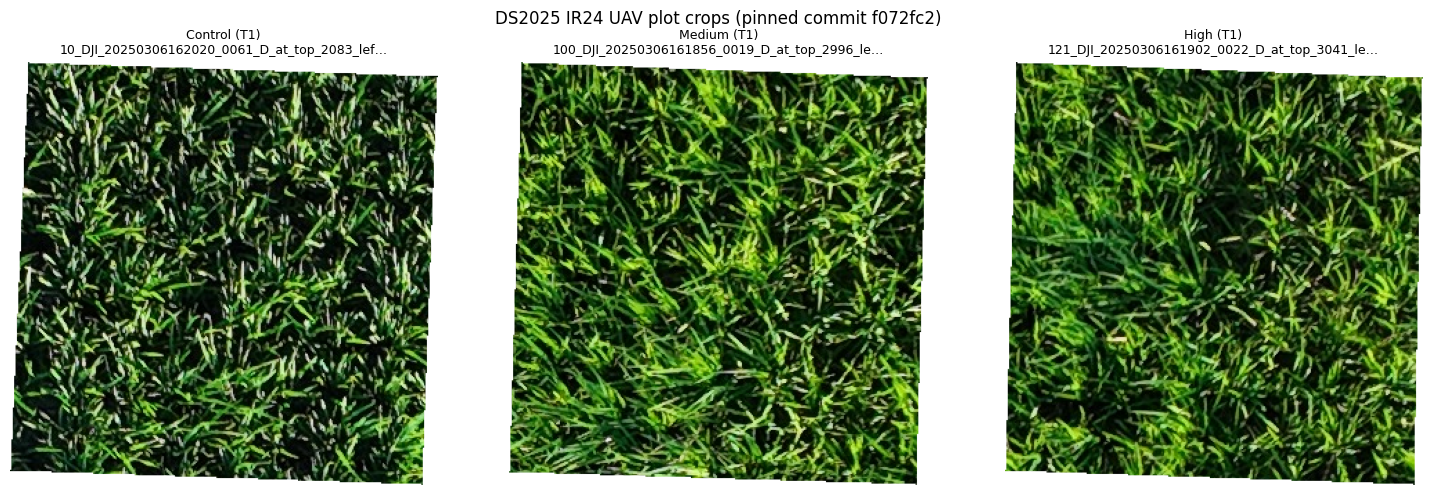

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, sev in zip(axes, ("Control", "Medium", "High")):
    sample = sorted((DATA_ROOT / sev / "T1").glob("*.png"))[0]
    ax.imshow(mpimg.imread(sample))
    ax.set_title(f"{sev} (T1)\n{sample.name[:44]}…", fontsize=9)
    ax.axis("off")
plt.suptitle("DS2025 IR24 UAV plot crops (pinned commit f072fc2)", fontsize=12)
plt.tight_layout()
plt.savefig("/content/input_preview.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Build the YOLO classification dataset — author's plant-wise split

Replicate `Data_Preprocessing.ipynb`: group images by `(severity, plant_id)` across **all** time points,
shuffle plants within each severity with seed 42, and assign whole plants to train/val/test at
0.80/0.15/0.05 so no plant appears in two splits (leakage audit included). Classes are named
`{Severity}_{T#}` (T1–T4 = weekly flights 2025-03-06/13/19/26; per the paper's study flow these are
15/23/29/36 days after inoculation). Images are copied into a YOLO-cls tree under
`/content/datasets/BLB_DS2025_IR24`.

**著者の植物単位分割（seed 42, 80/15/5, リーク無し）を再現し、YOLO-cls 形式のデータセットを構築します。**

In [ ]:
import shutil, random
from collections import defaultdict

SEVERITIES = ["Control", "Medium", "High"]
TIME_PERIODS = ["T1", "T2", "T3", "T4"]
SPLIT = (0.80, 0.15, 0.05)
SEED = 42
OUT = Path("/content/datasets/BLB_DS2025_IR24")

plant_images = defaultdict(list)
for sev in SEVERITIES:
    for tp in TIME_PERIODS:
        for f in sorted((DATA_ROOT / sev / tp).glob("*.png")):
            plant_id = re.match(r"(\d+)_", f.stem).group(1)
            plant_images[(sev, plant_id)].append((f"{sev}_{tp}", f))

random.seed(SEED)
split_of_plant = {}
buckets = {s: defaultdict(list) for s in ("train", "val", "test")}
for sev in SEVERITIES:
    keys = sorted([k for k in plant_images if k[0] == sev], key=lambda x: int(x[1]))
    random.shuffle(keys)
    n_tr, n_val = int(round(len(keys) * SPLIT[0])), int(round(len(keys) * SPLIT[1]))
    for i, pk in enumerate(keys):
        split = "train" if i < n_tr else ("val" if i < n_tr + n_val else "test")
        split_of_plant[pk] = split
        for cls, f in plant_images[pk]:
            buckets[split][cls].append(f)

# Leakage audit (author cell 4b): every plant must live in exactly one split
plant_splits = defaultdict(set)
for pk, sp in split_of_plant.items():
    plant_splits[pk].add(sp)
assert all(len(v) == 1 for v in plant_splits.values()), "plant-identity leakage detected"
print("No plant-identity leakage: every (severity, plant) group is in exactly one split.")

if OUT.exists():
    shutil.rmtree(OUT)
for split, bucket in buckets.items():
    for cls, files in bucket.items():
        dst = OUT / split / cls
        dst.mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy2(f, dst / f"{cls}_{f.name}")

for split in ("train", "val", "test"):
    total = sum(len(v) for v in buckets[split].values())
    print(f"{split}: {total} images across {len(buckets[split])} classes")

No plant-identity leakage: every (severity, plant) group is in exactly one split.


train: 2772 images across 12 classes
val: 504 images across 12 classes
test: 180 images across 12 classes


## 8. Fine-tune YOLOv26-nano (author training recipe, placeholders resolved)

Follow `YOLO_Training_DS2025.ipynb`: load COCO-pretrained `yolo26n-cls.pt` and transfer-learn on the
dataset above with the authors' `epochs=100` / `patience=10`. **Adaptations (documented):** the author
notebook leaves `IMG_SIZE`/`BATCH_SIZE` as placeholders, so we use `imgsz=224` (Ultralytics classification
default) and `batch=64` (fits a T4); on this subset, early stopping typically ends training well before
100 epochs. This reduced-scale run is **not** expected to match the paper's dataset-level accuracies
(e.g., 75.94% average) quantitatively.

**著者の手順に従い `yolo26n-cls.pt` を転移学習します（epochs=100, patience=10 は著者指定のまま、
imgsz/batch は著者がプレースホルダにしたためデフォルト値を使用。本デモは縮小スケールであり、
論文の精度値そのものの再現は期待しません）。**

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n-cls.pt")  # COCO-pretrained YOLOv26-nano classifier (auto-downloads ~10 MB)
model.train(
    data=str(OUT),
    epochs=100,          # author value (YOLO_Training_DS2025.ipynb)
    patience=10,         # author value
    imgsz=224,           # ultralytics default (author placeholder IMG_SIZE)
    batch=64,            # chosen for T4 16 GB (author placeholder BATCH_SIZE)
    project="/content/runs",
    name="blb_ds2025_ir24",
    exist_ok=True,
    verbose=True,
)
best_path = Path(model.trainer.best)
print("Best weights:", best_path)

Ultralytics 8.4.186 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/BLB_DS2025_IR24, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=blb_ds2025_ir24, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=Tr

train: /content/datasets/BLB_DS2025_IR24/train... found 2772 images in 12 classes ✅ 


val: /content/datasets/BLB_DS2025_IR24/val... found 504 images in 12 classes ✅ 


test: /content/datasets/BLB_DS2025_IR24/test... found 180 images in 12 classes ✅ 


...

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 4/4 1.9it/s 2.1s

                   all      0.458          1


Speed: 0.8ms preprocess, 2.4ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /content/runs/blb_ds2025_ir24


Best weights: /content/runs/blb_ds2025_ir24/weights/best.pt


## 9. Validation — normalized confusion matrix (author metrics procedure)

Replicate `Customized_YOLO_Classification_Metrics.ipynb` on the **val** split: build the raw confusion
matrix, normalize each true-class column to percent, and plot with a dry-season-style palette.
**Adaptation (documented):** the current Ultralytics classification validator does not expose the
`metrics.confusion_matrix` object the authors' notebook read, so we compute per-image predictions with
the trained checkpoint and assemble the same `[predicted, true]` count matrix; the authors'
normalization and plotting logic is then applied unchanged.

**著者の評価手順に従い、val 分割の混同行列を列正規化（%）して描画します。現在の Ultralytics は著者
ノートブックが参照する混同行列オブジェクトを直接提供しないため、画像ごとの予測から同一形式の行列を
構築します（明示した適応）。**

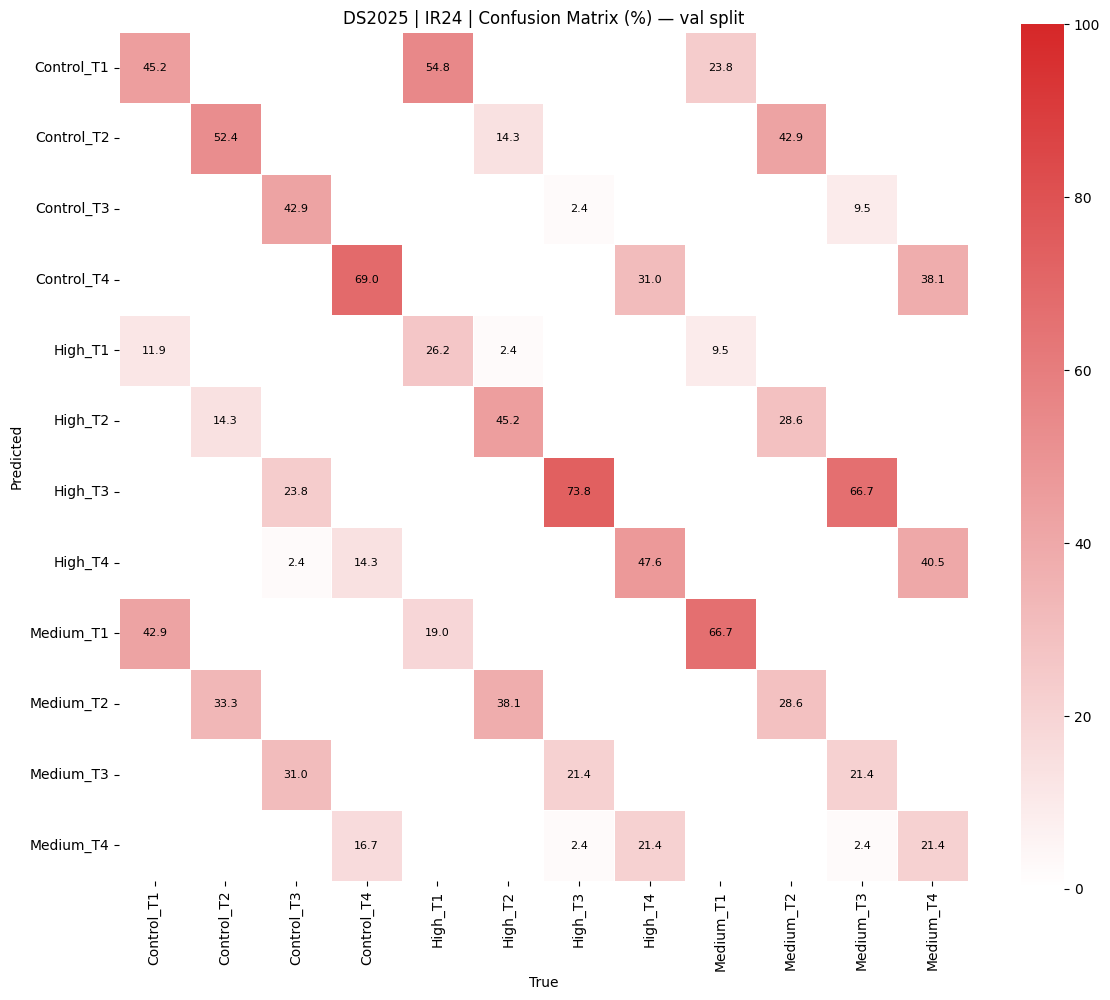

Classes: ['Control_T1', 'Control_T2', 'Control_T3', 'Control_T4', 'High_T1', 'High_T2', 'High_T3', 'High_T4', 'Medium_T1', 'Medium_T2', 'Medium_T3', 'Medium_T4']


In [ ]:
import numpy as np
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

best = YOLO(str(best_path))
class_names = list(best.names.values())
nc = len(class_names)
cm_raw = np.zeros((nc, nc), dtype=int)  # [predicted, true], author orientation

val_root = OUT / "val"
for true_idx, cls in enumerate(class_names):
    for img in sorted((val_root / cls).glob("*.png")):
        res = best.predict(source=str(img), imgsz=224, verbose=False)[0]
        cm_raw[res.probs.top1, true_idx] += 1

col_sums = cm_raw.sum(axis=0, keepdims=True)
col_sums[col_sums == 0] = 1
cm_norm = (cm_raw / col_sums) * 100.0

custom_cmap = LinearSegmentedColormap.from_list("custom_cmap", ["#FFFFFF", "#d62728"])
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm_norm, annot=False, cmap=custom_cmap, cbar=True, square=True,
            linewidths=0.5, linecolor="white", xticklabels=class_names, yticklabels=class_names,
            vmin=0, vmax=100, ax=ax)
for i in range(nc):
    for j in range(nc):
        if cm_norm[i, j] > 0:
            ax.text(j + 0.5, i + 0.5, f"{cm_norm[i, j]:.1f}", ha="center", va="center",
                    color="black", fontsize=8)
ax.set_title("DS2025 | IR24 | Confusion Matrix (%) — val split")
ax.set_xlabel("True"); ax.set_ylabel("Predicted")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("/content/confusion_matrix_val.png", dpi=120, bbox_inches="tight")
plt.show()
print("Classes:", class_names)

## 10. Classification metrics — accuracy, precision, recall, F1 (author cell 12)

Reconstruct `y_true`/`y_pred` from the raw confusion-matrix counts exactly as the authors do, then emit
the sklearn `classification_report` and overall accuracy. Also aggregate accuracy per inoculation group
(Control/Medium/High) to compare with the paper's qualitative finding that high-inoculation plots are
detected most accurately (best single result: 86.21% IR24 High at 23 DAI, dry season).

**混同行列から sklearn の分類レポートと精度を再現し、接種レベル別の精度も集計します。**

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

y_true, y_pred = [], []
for pred in range(cm_raw.shape[0]):
    for true in range(cm_raw.shape[1]):
        c = int(cm_raw[pred, true])
        if c:
            y_true += [true] * c
            y_pred += [pred] * c
y_true, y_pred = np.array(y_true), np.array(y_pred)

print(classification_report(y_true, y_pred, labels=list(range(nc)),
                            target_names=class_names, digits=4, zero_division=0))
val_acc = accuracy_score(y_true, y_pred)
print(f"Overall Accuracy (val): {val_acc:.4f}")

group_acc = {}
for g in ("Control", "Medium", "High"):
    idx = [i for i, n in enumerate(class_names) if n.startswith(g)]
    m = [(t, p) for t, p in zip(y_true, y_pred) if t in idx]
    group_acc[g] = float(np.mean([t == p for t, p in m]))
print("Per-inoculation-group accuracy (val):", {k: round(v, 4) for k, v in group_acc.items()})

              precision    recall  f1-score   support

  Control_T1     0.3654    0.4524    0.4043        42
  Control_T2     0.4783    0.5238    0.5000        42
  Control_T3     0.7826    0.4286    0.5538        42
  Control_T4     0.5000    0.6905    0.5800        42
     High_T1     0.5238    0.2619    0.3492        42
     High_T2     0.5135    0.4524    0.4810        42
     High_T3     0.4493    0.7381    0.5586        42
     High_T4     0.4545    0.4762    0.4651        42
   Medium_T1     0.5185    0.6667    0.5833        42
   Medium_T2     0.2857    0.2857    0.2857        42
   Medium_T3     0.2903    0.2143    0.2466        42
   Medium_T4     0.3333    0.2143    0.2609        42

    accuracy                         0.4504       504
   macro avg     0.4579    0.4504    0.4390       504
weighted avg     0.4579    0.4504    0.4390       504

Overall Accuracy (val): 0.4504
Per-inoculation-group accuracy (val): {'Control': 0.5238, 'Medium': 0.3452, 'High': 0.4821}


## 11. Held-out test split check and results export

The authors reserve 5% of plants for testing; evaluate the best checkpoint on the test split the same
way and export a small results CSV. Single-season, single-variety results are a demonstration, not a
verification of the paper's dataset-level claims.

**テスト分割でも同じ評価を行い、結果を CSV に保存します（単一シーズン/品種のデモであり、
論文のデータセット全体の主張の検証ではありません）。**

In [ ]:
cm_test = np.zeros((nc, nc), dtype=int)
for true_idx, cls in enumerate(class_names):
    for img in sorted((OUT / "test" / cls).glob("*.png")):
        res = best.predict(source=str(img), imgsz=224, verbose=False)[0]
        cm_test[res.probs.top1, true_idx] += 1

y_t, y_p = [], []
for pred in range(cm_test.shape[0]):
    for true in range(cm_test.shape[1]):
        c = int(cm_test[pred, true])
        if c:
            y_t += [true] * c
            y_p += [pred] * c
test_acc = accuracy_score(np.array(y_t), np.array(y_p))
print(f"Overall Accuracy (test): {test_acc:.4f}")

rows = [{"split": "val", "accuracy": val_acc,
         **{f"acc_{k}": round(v, 4) for k, v in group_acc.items()}},
        {"split": "test", "accuracy": test_acc}]
results_df = pd.DataFrame(rows)
results_df.to_csv("/content/blb_ds2025_ir24_results.csv", index=False)
results_df

Overall Accuracy (test): 0.5111


,split,accuracy,acc_Control,acc_Medium,acc_High
0,val,0.450397,0.5238,0.3452,0.4821
1,test,0.511111,NaN,NaN,NaN


## 12. Interpretation and references

**What this run shows** (from the actual outputs above): the fine-tuned YOLOv26-nano classifier's
val/test accuracy and per-group breakdown on DS2025/IR24, obtained with the authors' own split, training
recipe, and evaluation code paths at pinned commit `f072fc2`. Expect the High-inoculation class to be
recognized most reliably, qualitatively consistent with the paper's best results (86.21% IR24 High at
23 DAI, dry season) — but this reduced single-season run does not validate the paper's 75.94% average
or its full-season figures.

**Limitations / 注意事項:** author placeholders (imgsz/batch) resolved to defaults; no fine-tuned author
weights exist to compare against; manual-score regression, WS2025/SL8H, and the Kruskal–Wallis analysis
are out of scope; the repository carries no LICENSE file — cited for scholarly reproduction only.

**References**
- Paper: DOI 10.21203/rs.3.rs-11163942/v1 (Research Square preprint v1)
- Code: https://github.com/cbalingbing/BLB_Detection_using_YOLOV26 @ `f072fc2684e1652e3918ec6de8db503d7514bcca`
  (`Training_scripts/Data_Preprocessing.ipynb`, `Training_scripts/Dry_Season/YOLO_Training_DS2025.ipynb`,
  `Training_scripts/Customized_YOLO_Classification_Metrics.ipynb`)
- Model: Ultralytics YOLO26 (https://docs.ultralytics.com/models/yolo26/)